# SmartLoan – Loan Eligibility Prediction

## 3. Exploratory Data Analysis

### Objective
To explore the dataset, identify patterns and understand how applicant information relates to historical loan approval decisions.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/train_u6lujuX_CVtuZ9i.csv")

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


### 3.1 Loan Approval Distribution

To understand the number of approved and rejected loan applications.

In [2]:
df["Loan_Status"].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

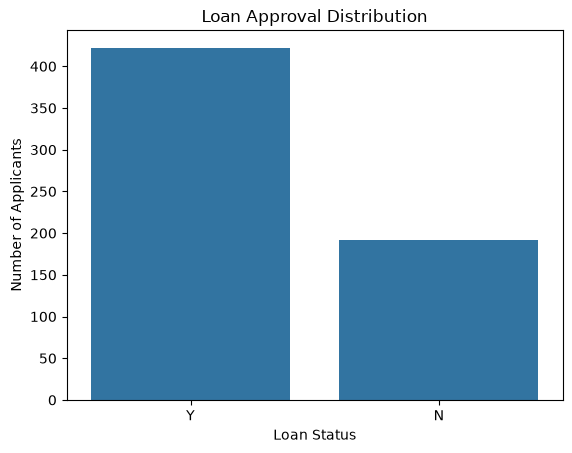

In [3]:
sns.countplot(data=df, x="Loan_Status")
plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

### 3.2 Applicant Income vs Loan Approval

To compare applicant income across approved and rejected loan applications.

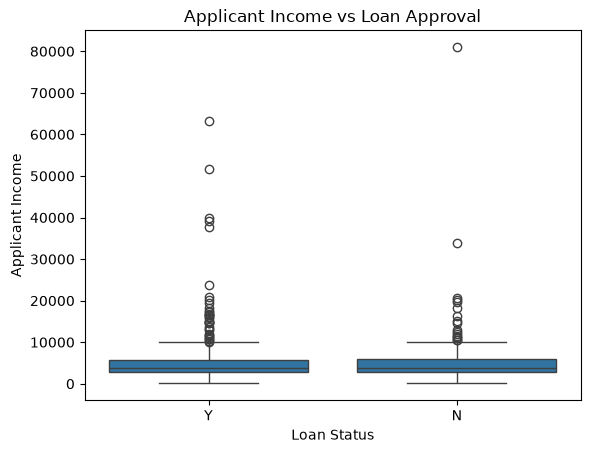

In [4]:
sns.boxplot(data=df, x="Loan_Status", y="ApplicantIncome")
plt.title("Applicant Income vs Loan Approval")
plt.xlabel("Loan Status")
plt.ylabel("Applicant Income")
plt.show()

**Observation:**
The income distributions of approved and rejected applicants overlap considerably. Applicant income alone does not clearly determine loan approval.

### 3.3 Co-applicant Income vs Loan Approval

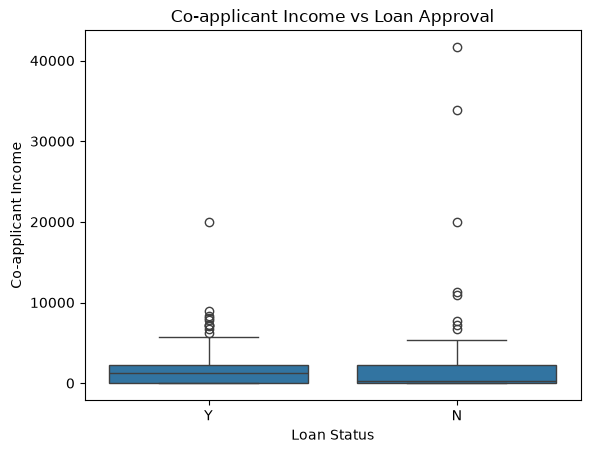

In [5]:
sns.boxplot(data=df, x="Loan_Status", y="CoapplicantIncome")
plt.title("Co-applicant Income vs Loan Approval")
plt.xlabel("Loan Status")
plt.ylabel("Co-applicant Income")
plt.show()

**Observation:**
Approved and rejected applicants have similar co-applicant income distributions. Many applicants have zero co-applicant income. Therefore, co-applicant income alone is not sufficient to determine loan approval.

### 3.4 Loan Amount vs Loan Approval

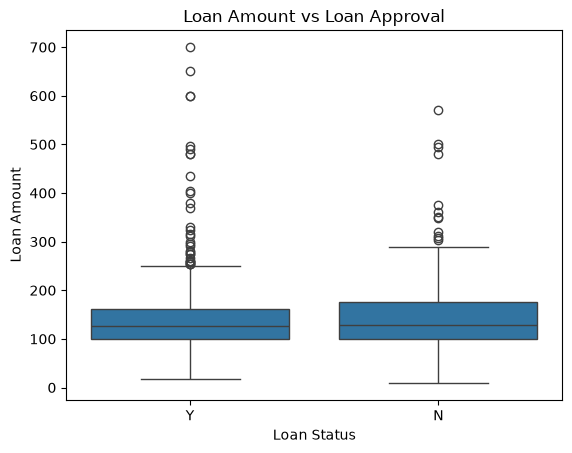

In [6]:
sns.boxplot(data=df, x="Loan_Status", y="LoanAmount")
plt.title("Loan Amount vs Loan Approval")
plt.xlabel("Loan Status")
plt.ylabel("Loan Amount")
plt.show()

**Observation:**
Approved and rejected applicants have similar loan amount distributions. Some unusually high loan amounts are present in both groups. Therefore, loan amount alone is not sufficient to determine loan approval.

### 3.5 Credit History vs Loan Approval

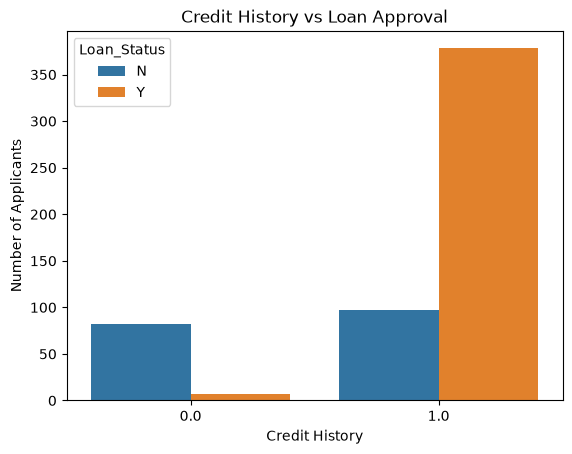

In [7]:
sns.countplot(data=df, x="Credit_History", hue="Loan_Status")
plt.title("Credit History vs Loan Approval")
plt.xlabel("Credit History")
plt.ylabel("Number of Applicants")
plt.show()

**Observation:**
Applicants with a satisfactory credit history (1) have a much higher number of loan approvals than applicants with an unsatisfactory credit history (0). This indicates that credit history is strongly associated with loan approval.

### 3.6 Education vs Loan Approval

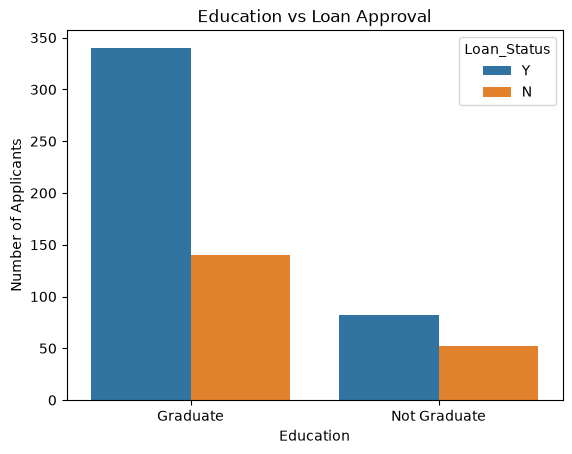

In [8]:
sns.countplot(data=df, x="Education", hue="Loan_Status")
plt.title("Education vs Loan Approval")
plt.xlabel("Education")
plt.ylabel("Number of Applicants")
plt.show()

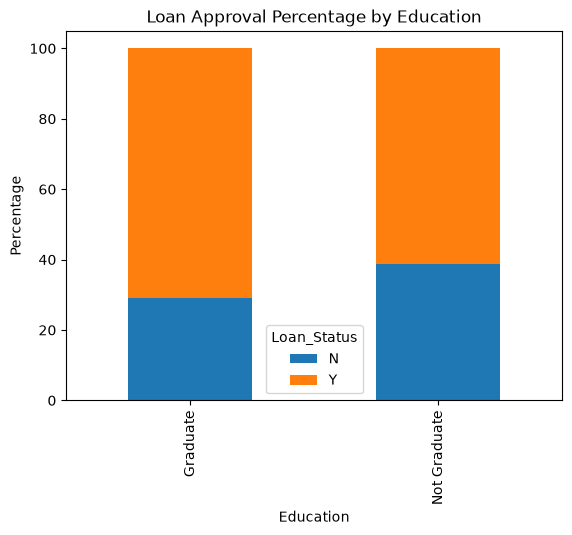

In [9]:
education_rate = pd.crosstab(
    df["Education"],
    df["Loan_Status"],
    normalize="index"
) * 100

education_rate.plot(kind="bar", stacked=True)

plt.title("Loan Approval Percentage by Education")
plt.xlabel("Education")
plt.ylabel("Percentage")
plt.show()

**Observation:**
Graduates have a higher loan approval percentage than non-graduates in this dataset. This suggests that education level may be associated with loan approval.

### 3.7 Marital Status vs Loan Approval

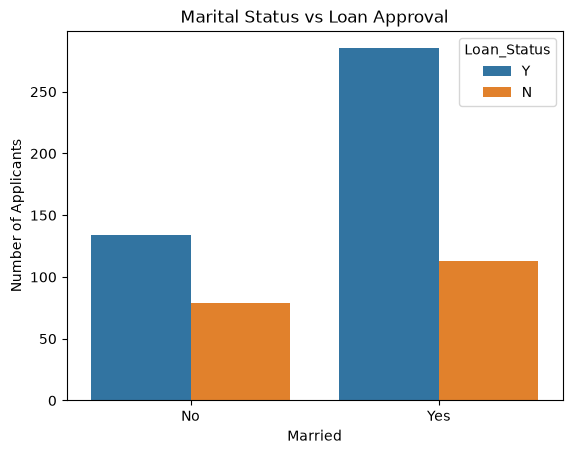

In [10]:
sns.countplot(data=df, x="Married", hue="Loan_Status")
plt.title("Marital Status vs Loan Approval")
plt.xlabel("Married")
plt.ylabel("Number of Applicants")
plt.show()

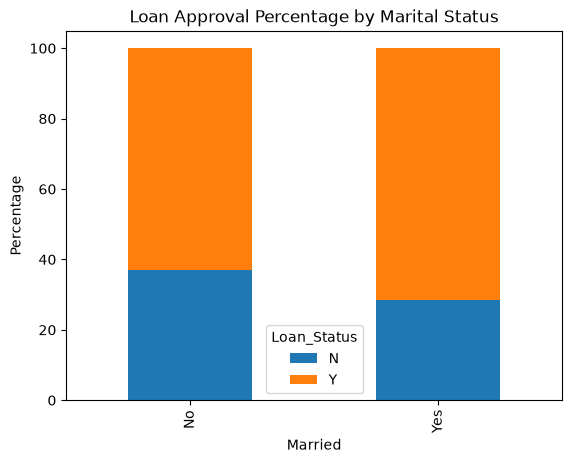

In [11]:
married_rate = pd.crosstab(
    df["Married"],
    df["Loan_Status"],
    normalize="index"
) * 100

married_rate.plot(kind="bar", stacked=True)

plt.title("Loan Approval Percentage by Marital Status")
plt.xlabel("Married")
plt.ylabel("Percentage")
plt.show()

**Observation:**
Married applicants have a higher loan approval percentage than unmarried applicants in this dataset. This suggests a possible association between marital status and loan approval.

### 3.8 Property Area vs Loan Approval

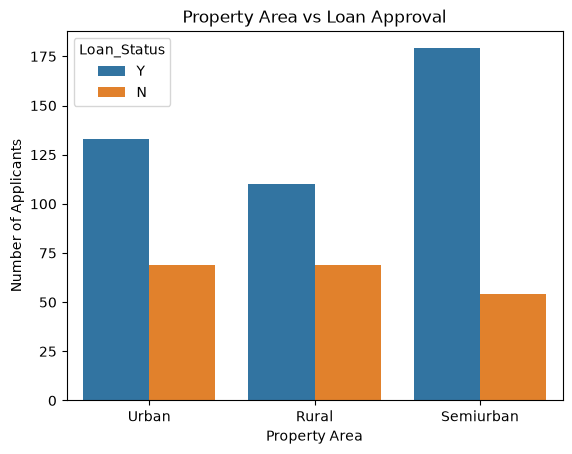

In [12]:
sns.countplot(data=df, x="Property_Area", hue="Loan_Status")
plt.title("Property Area vs Loan Approval")
plt.xlabel("Property Area")
plt.ylabel("Number of Applicants")
plt.show()

**Observation:**
Semiurban areas have the highest number of approved applicants, followed by urban and rural areas. Property area may be associated with loan approval.

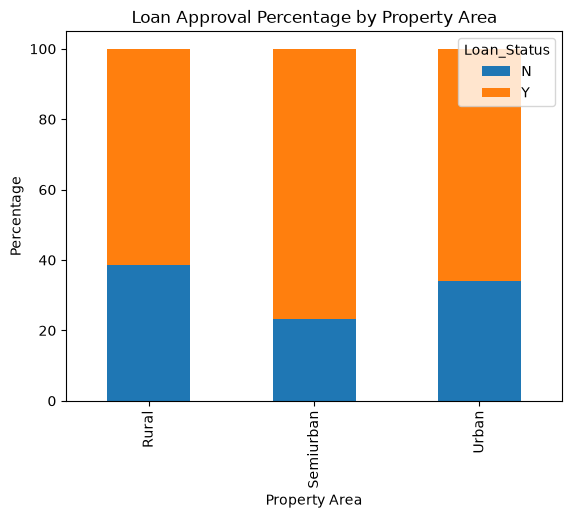

In [13]:
area_rate = pd.crosstab(
    df["Property_Area"],
    df["Loan_Status"],
    normalize="index"
) * 100

area_rate.plot(kind="bar", stacked=True)

plt.title("Loan Approval Percentage by Property Area")
plt.xlabel("Property Area")
plt.ylabel("Percentage")
plt.show()

**Observation:**
Rural applicants have the highest loan approval percentage, followed by semiurban and urban applicants. This suggests that property area is associated with historical loan approval.

### 3.9 Gender vs Loan Approval

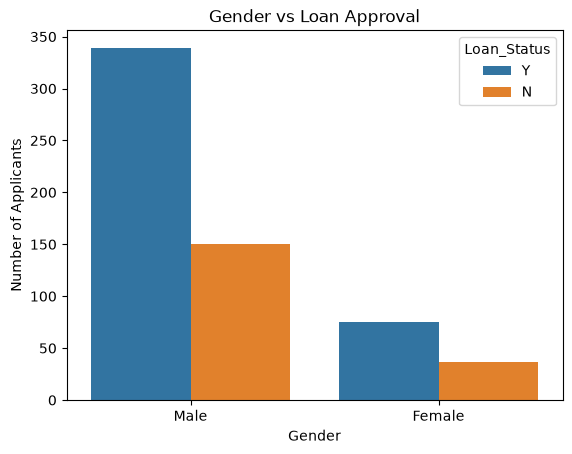

In [14]:
sns.countplot(data=df, x="Gender", hue="Loan_Status")
plt.title("Gender vs Loan Approval")
plt.xlabel("Gender")
plt.ylabel("Number of Applicants")
plt.show()

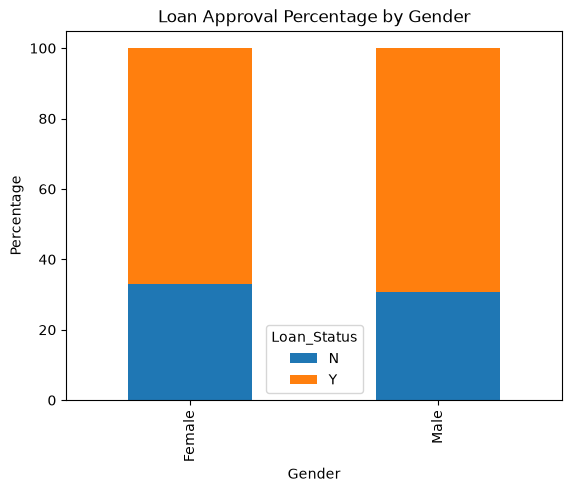

In [15]:
gender_rate = pd.crosstab(
    df["Gender"],
    df["Loan_Status"],
    normalize="index"
) * 100

gender_rate.plot(kind="bar", stacked=True)

plt.title("Loan Approval Percentage by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.show()

**Observation:**
Male applicants have a slightly higher loan approval percentage than female applicants in this dataset. However, the difference is small, and gender should be carefully evaluated for fairness before being used in a real-world lending system.

### 3.10 Self-Employment vs Loan Approval

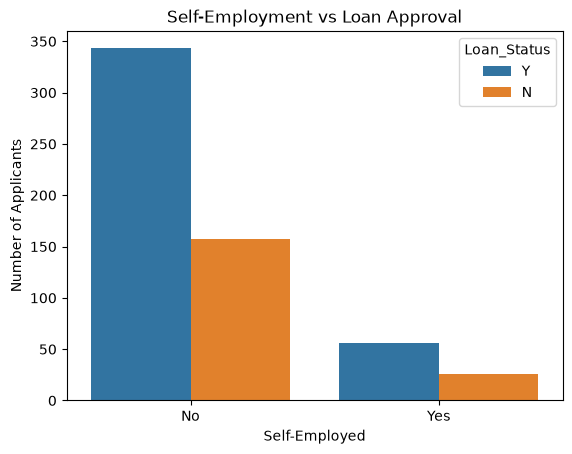

In [16]:
sns.countplot(data=df, x="Self_Employed", hue="Loan_Status")
plt.title("Self-Employment vs Loan Approval")
plt.xlabel("Self-Employed")
plt.ylabel("Number of Applicants")
plt.show()

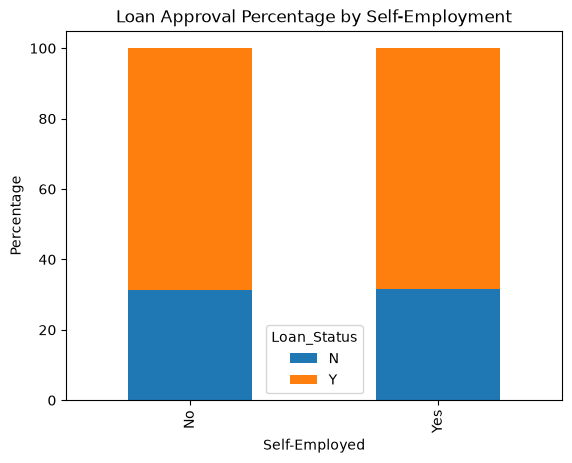

In [17]:
self_emp_rate = pd.crosstab(
    df["Self_Employed"],
    df["Loan_Status"],
    normalize="index"
) * 100

self_emp_rate.plot(kind="bar", stacked=True)

plt.title("Loan Approval Percentage by Self-Employment")
plt.xlabel("Self-Employed")
plt.ylabel("Percentage")
plt.show()

**Observation:**
Both self-employed and non-self-employed applicants have nearly identical loan approval percentages. Therefore, self-employment status alone does not appear to strongly distinguish approved and rejected applications in this dataset.

### 3.11 Dependents vs Loan Approval

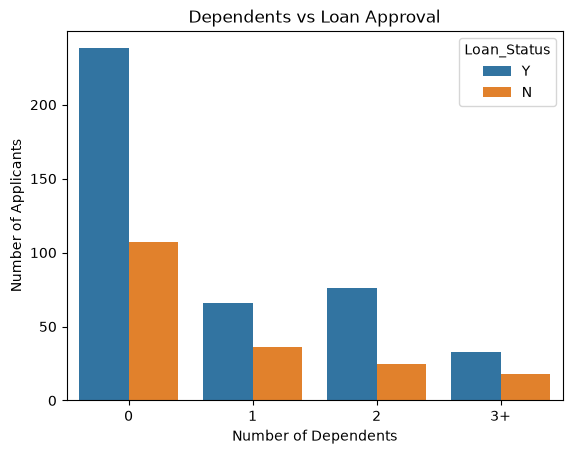

In [18]:
sns.countplot(data=df, x="Dependents", hue="Loan_Status")
plt.title("Dependents vs Loan Approval")
plt.xlabel("Number of Dependents")
plt.ylabel("Number of Applicants")
plt.show()

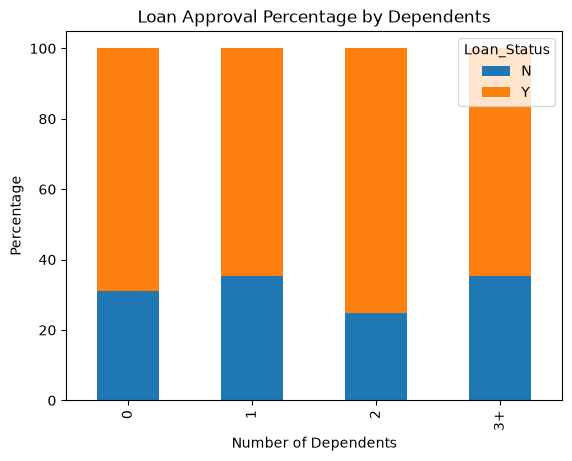

In [19]:
dependent_rate = pd.crosstab(
    df["Dependents"],
    df["Loan_Status"],
    normalize="index"
) * 100

dependent_rate.plot(kind="bar", stacked=True)

plt.title("Loan Approval Percentage by Dependents")
plt.xlabel("Number of Dependents")
plt.ylabel("Percentage")
plt.show()

**Observation:**
Applicants with two dependents have the highest approval percentage in this dataset. However, approval percentages remain relatively similar across all dependent categories. Therefore, the number of dependents alone may not be a strong predictor of loan approval.

### 3.12 Loan Amount Term vs Loan Approval

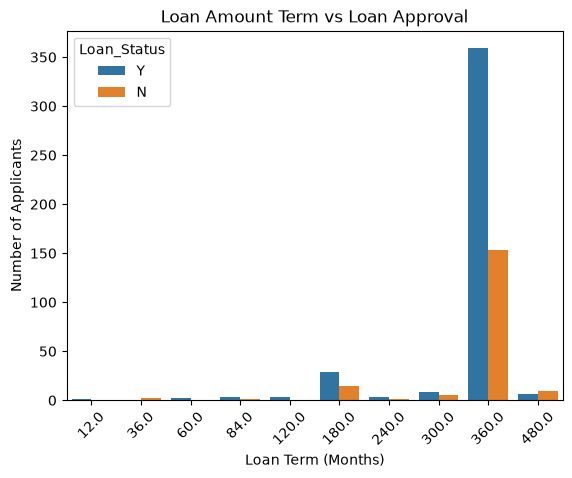

In [20]:
sns.countplot(data=df, x="Loan_Amount_Term", hue="Loan_Status")
plt.title("Loan Amount Term vs Loan Approval")
plt.xlabel("Loan Term (Months)")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=45)
plt.show()

**Observation:**
A 360-month loan term is the most common in the dataset. Other loan terms have comparatively fewer applications. This indicates an uneven distribution of loan-term categories. Loan tenure may be useful when analysed along with loan amount and applicant income.

In [21]:
df["Loan_Amount_Term"].value_counts().sort_index()

Loan_Amount_Term
12.0       1
36.0       2
60.0       2
84.0       4
120.0      3
180.0     44
240.0      4
300.0     13
360.0    512
480.0     15
Name: count, dtype: int64

**Observation:**
The 360-month loan term is dominant, accounting for 512 out of 600 non-missing records (approximately 85.3%). Other loan terms have comparatively fewer records. This uneven distribution should be considered during feature engineering and model evaluation.

In [22]:
term_rate = pd.crosstab(
    df["Loan_Amount_Term"],
    df["Loan_Status"],
    normalize="index"
) * 100

term_rate

Loan_Status,N,Y
Loan_Amount_Term,,
12.0,0.000000,100.000000
36.0,100.000000,0.000000
60.0,0.000000,100.000000
84.0,25.000000,75.000000
120.0,0.000000,100.000000
180.0,34.090909,65.909091
240.0,25.000000,75.000000
300.0,38.461538,61.538462
360.0,29.882812,70.117188


**Observation:**
The 360-month loan term has the largest number of applications, with an approval rate of approximately 70.12%. The 480-month category has a lower approval rate of 40%, but contains only 15 records. Rare loan-term categories have limited data, so their approval percentages should be interpreted cautiously.

### 3.13 Correlation Analysis

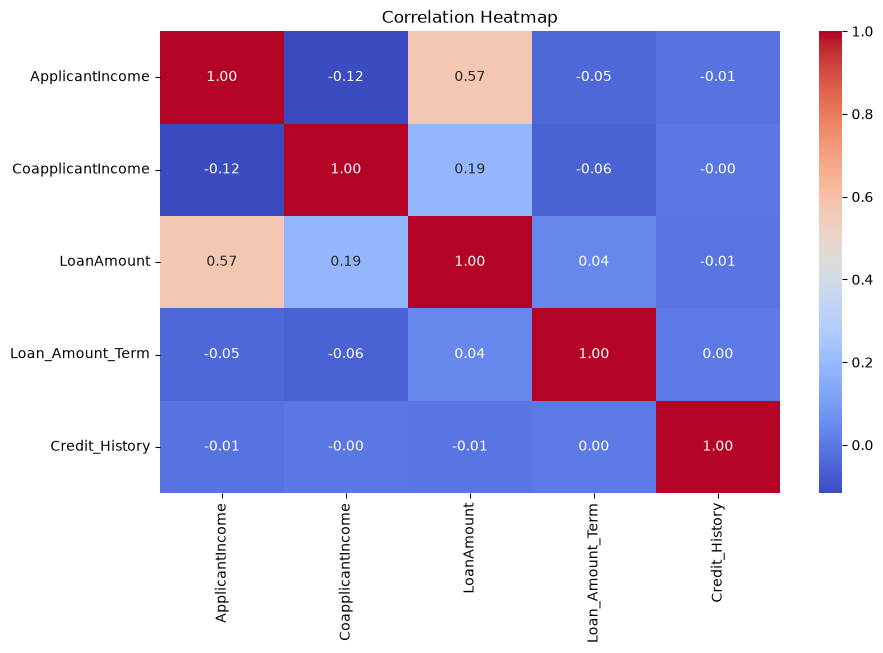

In [23]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

**Observation:**

ApplicantIncome and LoanAmount show a moderate positive correlation (0.57). CoapplicantIncome and LoanAmount show a weak positive correlation (0.19).

Most other numerical feature pairs have weak linear correlations.

These findings suggest that feature engineering, such as TotalIncome and LoanToIncomeRatio, may help improve model performance.

## 4. Overall EDA Findings

1. The dataset contains 422 approved and 192 rejected loan applications.
2. Credit History shows a strong association with loan approval.
3. Applicant Income, Coapplicant Income, and Loan Amount alone do not clearly separate approved and rejected applications.
4. Education, Marital Status, Property Area, Gender, Self-Employment, and Dependents show differences in approval percentages.
5. Most applicants have a loan term of 360 months (85.3% of non-missing records).
6. Applicant Income and Loan Amount show a moderate positive correlation (0.57).
7. Feature engineering may help create more useful information for model training.

### Conclusion

EDA helped us understand the dataset, identify important patterns, and decide which features may be useful for building a loan approval prediction model.